<a href="https://colab.research.google.com/github/mashadiyevasabina/AB_Test_Project/blob/main/A_B_test_project_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A/B test project

1. Project Overview

Bu layihədə A və B qrupları arasında aparılmış A/B testin nəticələri analiz edilmişdir. Əsas məqsəd B variantının istifadəçi davranışına və biznes göstəricilərinə təsirini A variantı ilə müqayisə etməkdir.

Analiz zamanı istifadəçi qrupları üzrə conversion rate və orta sifariş məbləği müqayisə edilmiş, nəticələrin statistik əhəmiyyətliliyi yoxlanılmış və potensial outlier-lərin nəticələrə təsiri araşdırılmışdır.

Layihənin əsas biznes sualı:

B variantı A variantı ilə müqayisədə istifadəçilərin alış-verişə çevrilmə ehtimalını artırırmı və bu dəyişiklik biznes gəliri baxımından statistik olaraq əhəmiyyətlidirmi?

In [ ]:
#Əvvəlcə pandas kitabxanasını import edək
import pandas as pd

2. Data Overview

Analiz üçün istifadə olunan məlumat setinə nəzər salaq

transactionid — sifarişin unikal identifikatoru

visitorid — istifadəçinin unikal identifikatoru

date — sifariş tarixi

revenue — sifariş məbləği

group — istifadəçinin A və ya B test qrupuna aidiyyəti




In [ ]:
# Drive.ı import edək
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# read_csv ilə cədvəllərimizi oxutduraq
hypothesis     = pd.read_csv("/content/drive/MyDrive/Statistika projekt/hypotheses_us.csv", sep=';')
orders       = pd.read_csv("/content/drive/MyDrive/Statistika projekt/orders_us.csv")
visitsdata    = pd.read_csv("/content/drive/MyDrive/Statistika projekt/visits_us.csv")


In [ ]:
hypothesis

,Hypothesis,Reach,Impact,Confidence,Effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1
5,Add a customer review page. This will increase...,3,2,2,3
6,Show banners with current offers and sales on ...,5,3,8,3
7,Add a subscription form to all the main pages....,10,7,8,5
8,Launch a promotion that gives users discounts ...,1,9,9,5


In [ ]:
hypothesis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 492.0+ bytes


In [ ]:
orders


,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
...,...,...,...,...,...
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A
1194,1807773912,573423106,2019-08-14,165.3,A
1195,1947021204,1614305549,2019-08-14,5.5,A


In [ ]:
#Sutun adlarini deyisek
orders.columns = orders.columns.str.lower()
orders

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
...,...,...,...,...,...
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A
1194,1807773912,573423106,2019-08-14,165.3,A
1195,1947021204,1614305549,2019-08-14,5.5,A


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionid  1197 non-null   int64  
 1   visitorid      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB


In [ ]:
orders['date'] = pd.to_datetime(orders['date'])
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   transactionid  1197 non-null   int64         
 1   visitorid      1197 non-null   int64         
 2   date           1197 non-null   datetime64[ns]
 3   revenue        1197 non-null   float64       
 4   group          1197 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 46.9+ KB


#Bəzi ziyarətçilər həm A, həm də B qrupuna düşmüş ola bilər bunu yoxlayib tapaq ve varsa silek

In [ ]:
# Əvvəlcə ziyaretcilerin unikal qruplarinin sayini tapaq görə qrupıaşdıraq və unikal qrup novunu saxlayaq
duplicated_visitors = orders.groupby('visitorid')['group'].nunique()
duplicated_visitors
# daha sonra grup sayı 1 dən cox olanı seçək
duplicated_visitors = duplicated_visitors[duplicated_visitors > 1].index
duplicated_visitors
# Indi neçə dənə istifadəçi olduğunu tapaq
len(duplicated_visitors)

58

### Həm A həm B qrpuna düşən istifadəçi sayı 58 dir. datanın təmiz olması üçün bu dublikatları silək



In [ ]:
filtered_orders= orders[~orders['visitorid'].isin(duplicated_visitors)]
filtered_orders

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
5,182168103,935554773,2019-08-15,35.0,B
...,...,...,...,...,...
1191,3592955527,608641596,2019-08-14,255.7,B
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A
1194,1807773912,573423106,2019-08-14,165.3,A


In [ ]:
visitsdata

,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756
...,...,...,...
57,2019-08-27,B,720
58,2019-08-28,B,654
59,2019-08-29,B,531
60,2019-08-30,B,490


In [ ]:
visitsdata['date']=pd.to_datetime(visitsdata['date'])
visitsdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    62 non-null     datetime64[ns]
 1   group   62 non-null     object        
 2   visits  62 non-null     int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.6+ KB


###Hipotezləri prioritetləşdirmək üçün ICE çərçivəsini tətbiq edək. Onları prioritet sırasına görə azalan qaydada çeşidləyək.

In [ ]:
hypothesis['ICE_score']=hypothesis['Impact']*hypothesis['Confidence']/hypothesis['Effort']
hypothesis.sort_values(by='ICE_score',ascending=False)


,Hypothesis,Reach,Impact,Confidence,Effort,ICE_score
8,Launch a promotion that gives users discounts ...,1,9,9,5,16.200000
0,Add two new channels for attracting traffic. T...,3,10,8,6,13.333333
7,Add a subscription form to all the main pages....,10,7,8,5,11.200000
6,Show banners with current offers and sales on ...,5,3,8,3,8.000000
2,Add product recommendation blocks to the store...,8,3,7,3,7.000000
1,Launch your own delivery service. This will sh...,2,5,4,10,2.000000
5,Add a customer review page. This will increase...,3,2,2,3,1.333333
3,Change the category structure. This will incre...,8,3,3,8,1.125000
4,Change the background color on the main page. ...,3,1,1,1,1.000000


#Hipotezləri prioritetləşdirmək üçün RICE çərçivəsini tətbiq edək. Onları prioritet sırasına görə azalan qaydada çeşidləyək.

In [ ]:
hypothesis['RICE_score']=hypothesis['Reach']*hypothesis['Impact']*hypothesis['Confidence']/hypothesis['Effort']
hypothesis.sort_values(by='RICE_score',ascending=False)

,Hypothesis,Reach,Impact,Confidence,Effort,ICE_score,RICE_score
7,Add a subscription form to all the main pages....,10,7,8,5,11.200000,112.0
2,Add product recommendation blocks to the store...,8,3,7,3,7.000000,56.0
0,Add two new channels for attracting traffic. T...,3,10,8,6,13.333333,40.0
6,Show banners with current offers and sales on ...,5,3,8,3,8.000000,40.0
8,Launch a promotion that gives users discounts ...,1,9,9,5,16.200000,16.2
3,Change the category structure. This will incre...,8,3,3,8,1.125000,9.0
1,Launch your own delivery service. This will sh...,2,5,4,10,2.000000,4.0
5,Add a customer review page. This will increase...,3,2,2,3,1.333333,4.0
4,Change the background color on the main page. ...,3,1,1,1,1.000000,3.0


###"Add a subscription form to all the main pages"(Əsas səhifələrə abunəlik formu qoymaq). ICE də 3 cü yerdə olasa da Rice də 1 ci yerə qalxdı çünki, reach(əhatə dairəsi) 10 dur. İCE də 1 ci yerdə duran "Launch a promotion that gives users discounts on their birthdays"..(Ad günü olan istifadəçilərə promosiya təkliflər) RICE də 5 ci oldu çünki, hər gün ad günü olan məhdud kütləyə şamil olunur təsir dairəsi azdır ona görə də reach 1 dir.

#1
###Qruplar üzrə kumulyativ (toplanan) gəlirin qrafikini quraq.


In [ ]:
# Hər qrup və tarix üzrə gündəlik gəlirləri tapaq
daily_revenue=filtered_orders.groupby(['group','date'])['revenue'].sum().reset_index()
daily_revenue

,group,date,revenue
0,A,2019-08-01,2266.6
1,A,2019-08-02,1468.3
2,A,2019-08-03,1815.2
3,A,2019-08-04,675.5
4,A,2019-08-05,1398.0
...,...,...,...
57,B,2019-08-27,1746.9
58,B,2019-08-28,1010.5
59,B,2019-08-29,1681.2
60,B,2019-08-30,3286.8


In [ ]:
# Daha sonra kumulyativ gəliri cumsum() funksiyasi ile hesablayaq
daily_revenue['cum_revenue'] = daily_revenue.groupby('group')['revenue'].cumsum()
daily_revenue

,group,date,revenue,cum_revenue
0,A,2019-08-01,2266.6,2266.6
1,A,2019-08-02,1468.3,3734.9
2,A,2019-08-03,1815.2,5550.1
3,A,2019-08-04,675.5,6225.6
4,A,2019-08-05,1398.0,7623.6
...,...,...,...,...
57,B,2019-08-27,1746.9,71885.0
58,B,2019-08-28,1010.5,72895.5
59,B,2019-08-29,1681.2,74576.7
60,B,2019-08-30,3286.8,77863.5


###Indi buna vizual olaraq qrafikde baxaq

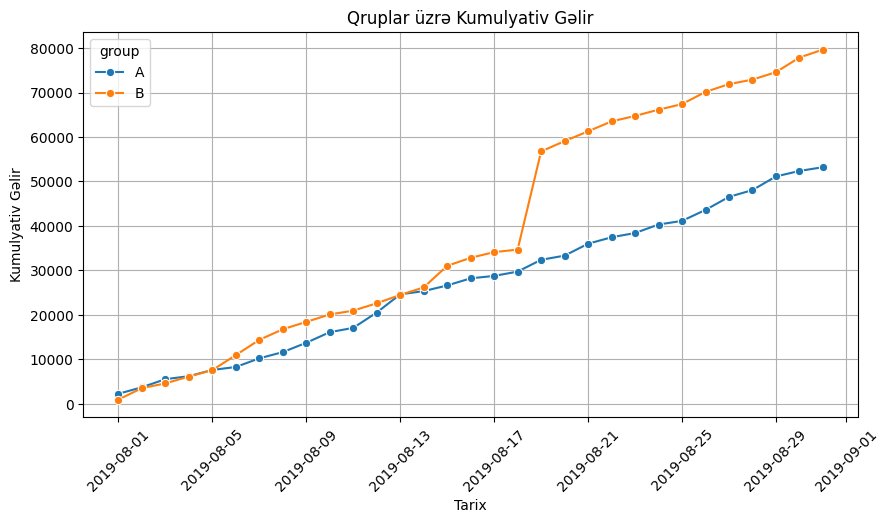

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=daily_revenue, x='date', y='cum_revenue', hue='group', marker='o'
)
plt.title('Qruplar üzrə Kumulyativ Gəlir')
plt.xlabel('Tarix')
plt.ylabel('Kumulyativ Gəlir')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

###B qrupu avqustun 17-19-u tarixləri arasında kəskin bir artım sıçrayışı yaşayıb (təxminən 35,000-dən 57,000-ə qalxıb). Bu, həmin tarixdə anomaliya yaradan çox böyük qiymətli sifarişin və ya həddindən artıq yüksək satış həcminin baş verdiyini gösterir.Dövriyyənin sonunda (avqustun sonu) B qrupu təxminən 80,000 gəlir səviyyəsinə çatdığı halda, A qrupu 53,000-55,000 civarında qalıb.B qrupu kumulyativ gəlir baxımından liderdir. Lakin 17-19 avqust tarixləri arasındakı kəskin artımın səbəbini (anomaliyaları/outlier-ləri) ayrıca analiz etmək tövsiyə olunur.

# 2

#Qruplar üzrə kumulyativ orta sifariş məbləğinin (average order size) qrafikini quraq.

In [ ]:
average_order_size=filtered_orders.groupby('group')['revenue'].mean()
average_order_size

,revenue
group,
A,113.700855
B,145.348905


(array([0, 1]), [Text(0, 0, 'A'), Text(1, 0, 'B')])

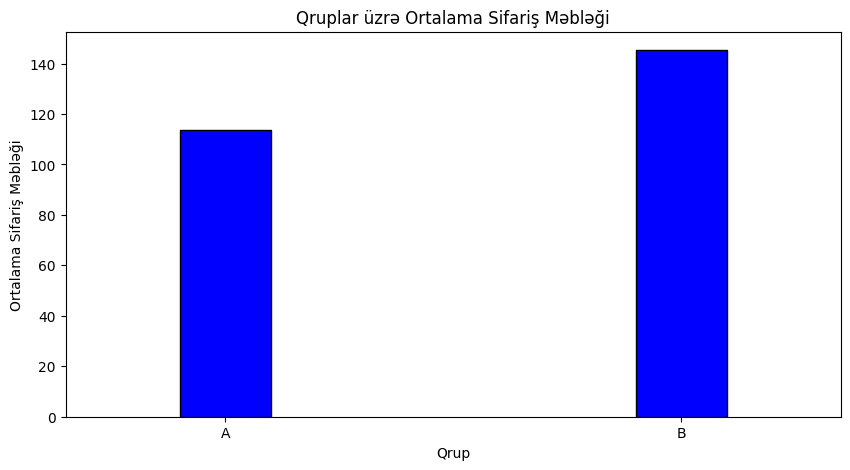

In [ ]:
filtered_orders.groupby('group')['revenue'].mean().plot(
    kind='bar',
    color='blue',
    width=0.2,
    edgecolor='black',
    figsize=(10, 5)
)

plt.title('Qruplar üzrə Ortalama Sifariş Məbləği')
plt.xlabel('Qrup')
plt.ylabel('Ortalama Sifariş Məbləği')
plt.xticks(rotation=0)

#B qrupu istifadecilerinin orta sifaris meblegi A qrupuna nezeren coxdur kimi gorunur. lakin analize davam edək

#3
#A qrupu ilə müqayisədə B qrupunun kumulyativ orta sifariş məbləğindəki nisbi fərqi tapaq

In [ ]:
# B qrupunun A ya nəzərən nisbi fərqi: (B / A) - 1
relative_difference = (
    average_order_size['B'] / average_order_size['A']
) - 1
relative_difference


np.float64(0.2783448769307837)

#alinan neticeden B qrupunda sifaris veren istifadeciler A qrupundan 27.83 faiz daha çox gəlir gətirdiyi musahide olunur

#4
##Hər bir gün üçün sifarişlərin ziyarət sayına nisbəti kimi hər qrupun konversiya dərəcəsini (conversion rate)hesablayaq. İki qrupun gündəlik konversiya dərəcələrinin qrafikini quraq və fərqi təsvir edek.


In [ ]:
print(list(filtered_orders.columns))

['transactionid', 'visitorid', 'date', 'revenue', 'group']


In [ ]:
transcount=filtered_orders.groupby(['group','date'],as_index=False)['transactionid'].count()

merged=transcount.merge(visitsdata,on=['group','date'])
merged['conversion']=merged['transactionid']/merged['visits']
merged

,group,date,transactionid,visits,conversion
0,A,2019-08-01,23,719,0.031989
1,A,2019-08-02,19,619,0.030695
2,A,2019-08-03,24,507,0.047337
3,A,2019-08-04,11,717,0.015342
4,A,2019-08-05,22,756,0.029101
...,...,...,...,...,...
57,B,2019-08-27,11,720,0.015278
58,B,2019-08-28,22,654,0.033639
59,B,2019-08-29,15,531,0.028249
60,B,2019-08-30,21,490,0.042857


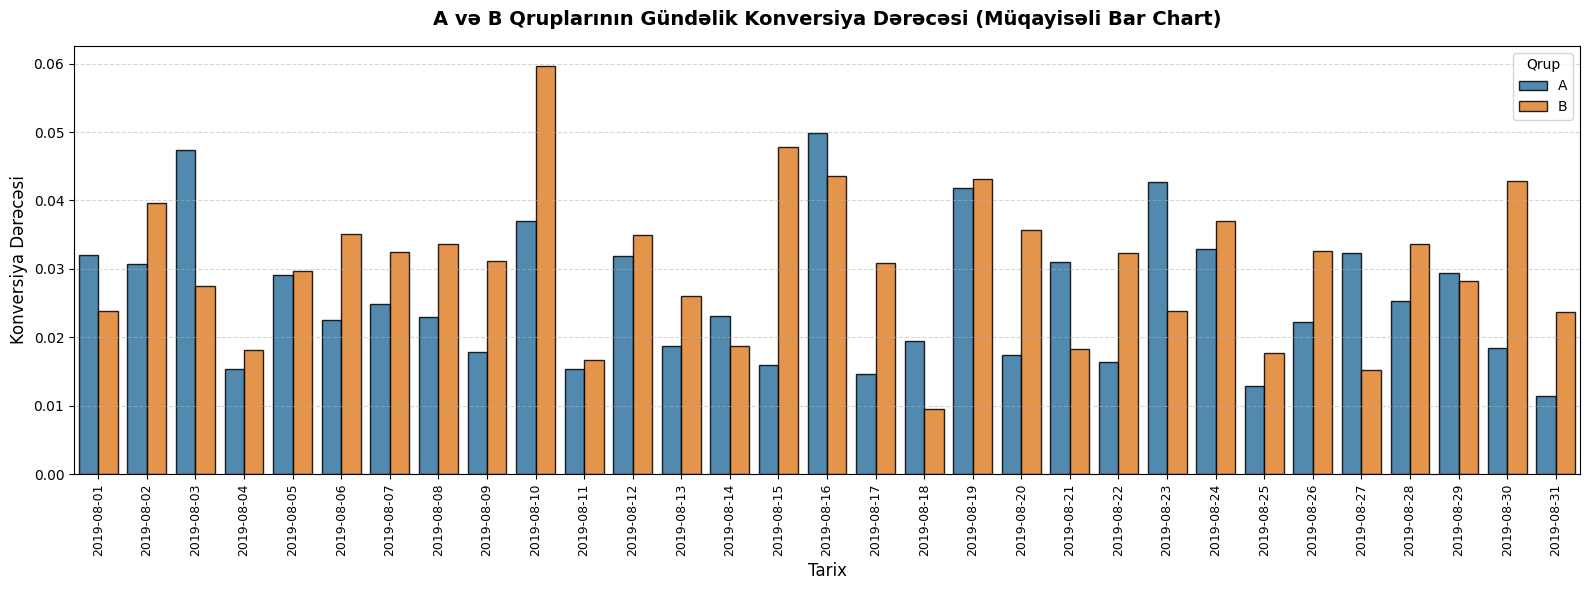

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Tarixi datetime formatına çeviririk
merged['date'] = pd.to_datetime(merged['date'])

# Tarixləri mətn formatına salırıq
merged['date_str'] = merged['date'].dt.strftime('%Y-%m-%d')

plt.figure(figsize=(16, 6))

# A və B qruplarını yan-yana sütunlar kimi qururuq
ax = sns.barplot(
    data=merged,
    x='date_str',
    y='conversion',
    hue='group',
    palette={'A': '#1f77b4', 'B': '#ff7f0e'}, # A üçün göy, B üçün narıncı
    edgecolor='black',
    alpha=0.85
)

# Qrafik tərtibatı
plt.title('A və B Qruplarının Gündəlik Konversiya Dərəcəsi (Müqayisəli Bar Chart)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tarix', fontsize=12)
plt.ylabel('Konversiya Dərəcəsi', fontsize=12)
plt.xticks(rotation=90, fontsize=9)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Qrup', frameon=True)

# Y oxunun sıfırdan başlamasını təmin edirik
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

### Burada sifaris sayinin ziyarət sayına bolunmesindən alınan əmsal nə qədər 1 ə yaxındırsa o qədər yaxşıdır. yəni bu, sayta daxil olanların boyuk əksəriyyəti alış verişi tamamlayıb deməkdir. ümumi ay ərzində 22  gün daha çox B qrupunda iştirak edən ziyarətçilər A qrupuna nisbətən alışverışərini sona çatdırmışlar.

#5
##İstifadəçi başına düşən sifariş sayının səpələnmə diаqramını (scatter chart) quraq.

In [ ]:
filtered_orders

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
5,182168103,935554773,2019-08-15,35.0,B
...,...,...,...,...,...
1191,3592955527,608641596,2019-08-14,255.7,B
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A
1194,1807773912,573423106,2019-08-14,165.3,A


In [ ]:
visitorsorders=filtered_orders.groupby(['visitorid', 'group'],as_index=False)['transactionid'].count()
visitorsorders=visitorsorders.rename(columns={'transactionid': 'transaction_count'})

visitorsorders

,visitorid,group,transaction_count
0,5114589,B,1
1,6958315,B,1
2,11685486,A,1
3,39475350,B,1
4,47206413,B,1
...,...,...,...
968,4259830713,A,1
969,4278982564,A,1
970,4279090005,B,1
971,4281247801,B,1


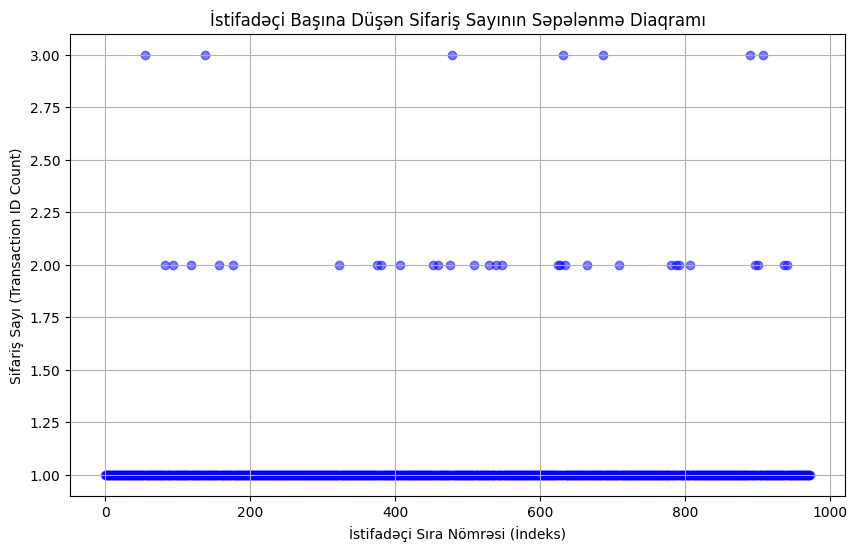

In [ ]:
import matplotlib.pyplot as plt

# X oxu üçün istifadəçi indekslərinin seriyasını yaradırıq
x_values = pd.Series(range(0, len(visitorsorders)))

# Qrafikin ölçüsünü təyin edirik
plt.figure(figsize=(10, 6))

# Scatter chart qurulması
plt.scatter(x_values, visitorsorders['transaction_count'], alpha=0.5, color='blue')

# Qrafik başlıqları və ox adları
plt.title('İstifadəçi Başına Düşən Sifariş Sayının Səpələnmə Diaqramı')
plt.xlabel('İstifadəçi Sıra Nömrəsi (İndeks)')
plt.ylabel('Sifariş Sayı (Transaction ID Count)')
plt.grid(True)

plt.show()

In [ ]:
visitorsorders['transaction_count'].value_counts()

,count
transaction_count,
1,937
2,29
3,7


### Qrafik və value_count() funksiyası ilə baxa bilərik ki bir ay ərzində əksər istifadəçilər 1 dəfə sifariş verib. 29 istifadəçi 2 dəfə, 7 istifadəçi isə 3 dəfə sifariş verib

#6

###İstifadəçi başına düşən sifariş sayının 95-ci və 99-cu persentillərini hesablayaq. Məlumat nöqtəsinin anomaliya hesab edildiyi həddi müəyyənləşdirək.

In [ ]:
# Her istifadecinin sifaris sayini tapaq
orders_per_user = filtered_orders.groupby('visitorid').agg({'transactionid': 'nunique'})
# Sutunun nadini deyisek
orders_per_user=orders_per_user.rename(columns={'transactionid':'order_count'})

orders_per_user.reset_index()

# Persentilləri hesablayaq
print(orders_per_user['order_count'].quantile([0.95, 0.99]))

0.95    1.0
0.99    2.0
Name: order_count, dtype: float64


##İstifadəçilərin 95%-dən çoxu yalnız 1 sifariş, 99%-dən çoxu isə maksimum 2 sifariş verib. Cəmi 7 nəfər (istifadəçilərin 1%-dən azı) 3 sifariş verib. Bu səbəbdən 2-dən çox sifariş verən (yəni 3 sifariş verən) istifadəçiləri anomaliya hesab edirik." buna gore de 2 ve daha kicik sifaris veren istifadecileri sececeyik


In [ ]:
filtered_orders_count = visitorsorders[
    visitorsorders['transaction_count'] < 3
]
filtered_orders_count

,visitorid,group,transaction_count
0,5114589,B,1
1,6958315,B,1
2,11685486,A,1
3,39475350,B,1
4,47206413,B,1
...,...,...,...
968,4259830713,A,1
969,4278982564,A,1
970,4279090005,B,1
971,4281247801,B,1


#7

##Sifariş qiymətlərinin (məbləğlərinin) səpələnmə diaqramını (scatter chart) quraq.

In [ ]:
filtered_orders

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
5,182168103,935554773,2019-08-15,35.0,B
...,...,...,...,...,...
1191,3592955527,608641596,2019-08-14,255.7,B
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A
1194,1807773912,573423106,2019-08-14,165.3,A


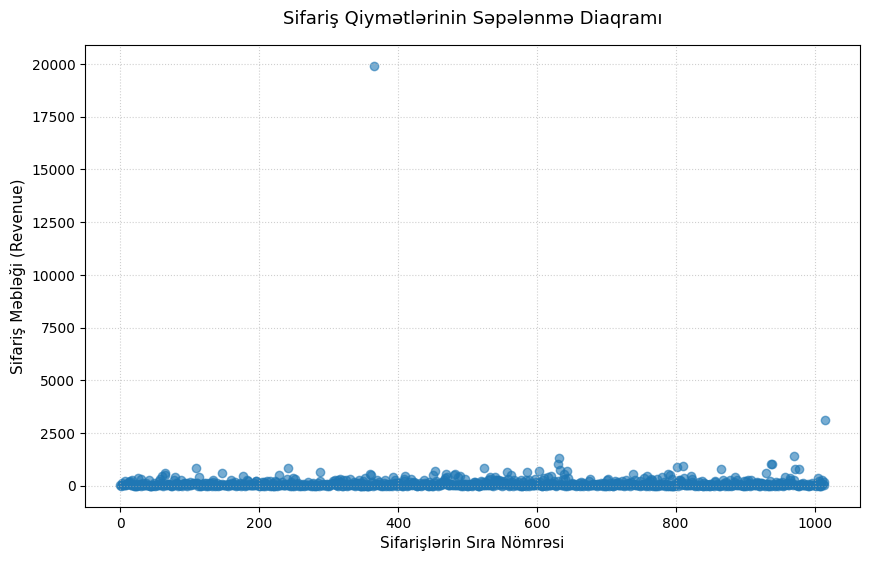

In [ ]:
import matplotlib.pyplot as plt

# X oxu üçün sıra nömrələri yaradırıq (0-dan sifariş sayına qədər)
x_values = pd.Series(range(0, len(filtered_orders['revenue'])))

plt.figure(figsize=(10, 6))

# Scatter plot qurulması
plt.scatter(x_values, filtered_orders['revenue'], alpha=0.6, color='tab:blue')

# Başlıq və oxların adlandırılması
plt.title('Sifariş Qiymətlərinin Səpələnmə Diaqramı', fontsize=13, pad=15)
plt.xlabel('Sifarişlərin Sıra Nömrəsi', fontsize=11)
plt.ylabel('Sifariş Məbləği (Revenue)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

## qrafikden iki  outlier oldugu gorunur bunlardan biri 3000 e yaxin digeri 20000 e yaxin bir reqemdir. A ve B gruplarindan gelen ortalama geliri hesablayarken bu reqemler orta qiymeti suni sekilde deyiserek duzgun qerar vermeyimize mane olacaq

#8

##Sifariş qiymətlərinin 95-ci və 99-cu persentillərini hesablayaq. Məlumat nöqtəsinin anomaliya hesab edildiyi həddi müəyyənləşdirək.

In [ ]:
# Persentilləri hesablayaq
print(filtered_orders['revenue'].quantile([0.95, 0.99]))

0.95    414.275
0.99    830.300
Name: revenue, dtype: float64


In [ ]:
orders_sorted = filtered_orders.sort_values(by='revenue', ascending=False)
orders_sorted.head(20)

,transactionid,visitorid,date,revenue,group
425,590470918,1920142716,2019-08-19,19920.4,B
1196,3936777065,2108080724,2019-08-15,3120.1,B
1136,666610489,1307669133,2019-08-13,1425.8,A
744,3668308183,888512513,2019-08-27,1335.6,B
743,3603576309,4133034833,2019-08-09,1050.0,A
1103,1348774318,1164614297,2019-08-12,1025.8,A
1099,316924019,148427295,2019-08-12,1015.9,A
949,1347999392,887908475,2019-08-21,930.0,A
940,2420050534,4003628586,2019-08-08,905.8,B
131,3163614039,2254586615,2019-08-22,830.3,A


##"Sifariş məbləğlərinin 99-cu persentili 830.300 təşkil edir.  ümumi sifarişlərin yalnız 1%-i bu məbləğdən yüksəkdir. Bu səbəbdən anomaliya həddi olaraq 830.3-dən yuxarı olan sifarişləri müəyyənləşdiririk və onları təmizlənmiş (filtered) A/B testi analizindən kənarlaşdıracağıq."

In [ ]:
filtered_orders_price=filtered_orders[filtered_orders['revenue']<=830.3]
filtered_orders_price
filtered_orders_price['revenue'].max()

830.3

#9

#Xam (xammal/ilkin) məlumatlardan istifadə edərək qruplar arasında konversiyadakı fərqin statistik əhəmiyyətini (statistical significance) tapaq

In [ ]:
# Konversiya sayini tapmaq ucun her qrupa gore sifaris saylarini visit saylarina bolmek lazimdir.
#əvvəlcə xam melumatdan istifade edceyimiz ucun orders cədvəlində grupa gore qruplasdirib tranzaksiyalarin yeni alis verislerin sayini tapaq
transaction_per_group=orders.groupby('group')['transactionid'].count()
transaction_per_group

,transactionid
group,
A,557
B,640


In [ ]:
# İndi visitdata cedvelinden grupa gore qruplasdirib visitlerin cemini tapaq.
visitssum_per_group=visitsdata.groupby('group')['visits'].sum()
visitssum_per_group

,visits
group,
A,18736
B,18916


In [ ]:
# Indi her qrup ucun konversiyalari hesablayaq
conversion = transaction_per_group /visitssum_per_group
conversion


,0
group,
A,0.029729
B,0.033834


In [ ]:
# Indi bu ferqi statistikaya uygun test edek
#Burada iki qrupun conversion-unu müqayisə etdiyimiz üçün iki proporsiya üçün z-test istifadə edə bilərik.
from statsmodels.stats.proportion import proportions_ztest

transaction_per_group = orders.groupby('group')['transactionid'].count()
visitssum_per_group = visitsdata.groupby('group')['visits'].sum()

stat, p_value = proportions_ztest(transaction_per_group,visitssum_per_group)

print('z-stat:', stat)
print('p-value:', p_value)

z-stat: -2.270005753735332
p-value: 0.02320723394441847


alfa dəyərini 0.05 goturek
əgər p_value > 0.05 o zaman H0 hipotezi: "A ve B qruplarının konversiyalari arasinda ferq yoxdur" dogrudur
əgər p_value < 0.05 o zaman H1 hipotezi:" A ve B qrupunun konversiyalari arasinda ferq var" dogrudur




In [ ]:
alpha=0.05
if p_value < alpha:
    print('H0 rədd edilir yəni H1 doğrudur   A ve B qrupunun konversiyalari arasinda statik əhəmiyyətli fərq var.')
else:
    print('H1 redd edilir yeni H0 dogrudur  A ve B qrupunun konversiyalari arasinda statistik əhəmiyyətli fərq yoxdur.')

H0 rədd edilir yəni H1 doğrudur   A ve B qrupunun konversiyalari arasinda statik əhəmiyyətli fərq var.


gorunduyu kimi p_value < 0.05 dən deməli H1 hipotezi dogrudur ve conversiyalar arasinda ferq var

#10

#Xam məlumatlardan istifadə edərək qruplar arasında orta sifariş məbləğindəki fərqin statistik əhəmiyyətini tapaq.

orta sifariş məbləği kimi kəmiyyət göstəricisinin iki müstəqil qrupun (A və B) ortalamalarını müqayisə edirik, buna görə t-test uyğun seçimdir. t-testi ucun iki deyisen lazim oldugu ucun ortalama geliri group by ile yox ayri ayri tapacagiq

In [ ]:
from scipy.stats import ttest_ind

# A və B qruplarında sifariş məbləğləri
orders_A = orders[orders['group'] == 'A']['revenue']
orders_B = orders[orders['group'] == 'B']['revenue']

# Orta sifariş məbləği
print(orders_A.mean())
print(orders_B.mean())



115.89748653500898
145.06343750000002


A ve B qruplarinin ayrica orta sifaris mebleglerini tapdiq.
indi Hipotezlerimizi yoxlamaq ucun t-testden istifade edib p value ni tapaq ve 0.05 alfamizdan boyuk yaxud kicik oldugunu arasdiraq



In [ ]:
# H0: A və B qruplarının orta sifariş məbləğləri bərabərdir
# H1: A və B qruplarının orta sifariş məbləğləri fərqlidir

stat, p_value = ttest_ind(orders_A, orders_B, equal_var=False)

print('t-stat:', stat)
print('p-value:', p_value)

alpha=0.05
if p_value < alpha:
    print('H0 rədd edilir yəni H1 doğrudur  qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq var.')
else:
    print('H1 redd edilir yeni H0 dogrudur qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq yoxdur.')


t-stat: -0.8886193336529402
p-value: 0.3745072295652421
H1 redd edilir yeni H0 dogrudur qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq yoxdur.


# Deməli xam məlumatlardan istifade ederken aldıq ki A və B qrupunun konversiyasi arasinda ferq var : B qrupunun konversiyasi daha coxdur.
# A və B qrupu arasinda isə əhəmiyyətli gəlir fərqi yoxdur

# Indi isə təmizlənmis datalarda bunlari yoxlayaq gorek ferq olacaqmi



#11

##Filtrlənmiş (anomaliyalardan təmizlənmiş) məlumatlardan istifadə edərək qruplar arasında konversiyadakı fərqin statistik əhəmiyyətini tapaq.

In [ ]:
# Konversiya sayini tapmaq ucun her qrupa gore temizlenmis sifaris saylarini temizlenmis visit saylarina bolmek lazimdir.buna gore filtered_orders cedvelinden istifade edeceyik
order_count=filtered_orders_count.groupby('group')['transaction_count'].sum()

visit_count=visitsdata.groupby('group')['visits'].sum()


conversion=order_count/visit_count*100
print(order_count)
print(visit_count)
print(conversion)

group
A    453
B    542
Name: transaction_count, dtype: int64
group
A    18736
B    18916
Name: visits, dtype: int64
group
A    2.417805
B    2.865299
dtype: float64


In [ ]:
# Indi bu ferqi statistikaya uygun test edek
#Burada iki qrupun conversion-unu müqayisə etdiyimiz üçün iki proporsiya üçün z-test istifadə edə bilərik.


order_count = filtered_orders.groupby('group')['transactionid'].count()
visit_count = visitsdata.groupby('group')['visits'].sum()

stat, p_value = proportions_ztest(transaction_per_group,visitssum_per_group)

print('z-stat:', stat)
print('p-value:', p_value)

z-stat: -2.270005753735332
p-value: 0.02320723394441847


In [ ]:

alpha = 0.05

if p_value < alpha:
    print('H0 rədd edilir yəni H1 doğrudur   A ve B qrupunun konversiyalari arasinda statistik əhəmiyyətli fərq var.')
else:
    print('H1 redd edilir yeni H0 dogrudur  A ve B qrupunun konversiyalari arasinda statistik əhəmiyyətli fərq yoxdur.')

H0 rədd edilir yəni H1 doğrudur   A ve B qrupunun konversiyalari arasinda statistik əhəmiyyətli fərq var.


#12

#Filtrlənmiş məlumatlardan istifadə edərək qruplar arasında orta sifariş məbləğindəki fərqin statistik əhəmiyyətini tapaq.

In [ ]:
filtered_orders_price

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B
5,182168103,935554773,2019-08-15,35.0,B
...,...,...,...,...,...
1190,38478481,1197745035,2019-08-14,135.3,B
1191,3592955527,608641596,2019-08-14,255.7,B
1192,2662137336,3733762160,2019-08-14,100.8,B
1193,2203539145,370388673,2019-08-14,50.1,A


In [ ]:


# A və B qruplarında sifariş məbləğləri
ordersA = filtered_orders_price[filtered_orders_price['group'] == 'A']['revenue']
ordersB =filtered_orders_price[filtered_orders_price['group'] == 'B']['revenue']

# Orta sifariş məbləği
print(ordersA.mean())
print(ordersB.mean())


103.16306695464363
99.9435661764706


In [ ]:
# H0: A və B qruplarının orta sifariş məbləğləri bərabərdir
# H1: A və B qruplarının orta sifariş məbləğləri fərqlidir

stat, p_value = ttest_ind(ordersA, ordersB, equal_var=False)

print('t-stat:', stat)
print('p-value:', p_value)

alpha=0.05
if p_value < alpha:
    print('H0 rədd edilir yəni H1 doğrudur  qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq var.')
else:
    print('H1 redd edilir yeni H0 dogrudur qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq yoxdur.')

t-stat: 0.37817269109847645
p-value: 0.7053857108372917
H1 redd edilir yeni H0 dogrudur qruplar arasında orta sifariş məbləğində statistik əhəmiyyətli fərq yoxdur.


#Deməli filtrlənmiş məlumatlarda da xam melumatlarda oldugu kimi qrupların konversiyalari arasinda ferq var ve B qrupu daha cox konversiyaya malikdir, Lakin hər iki qrupun gelirləri arasinda əhəmiyyətli bir ferq yoxdur

#Nəticə: A/B test nəticələrinə əsasən B qrupunda conversion göstəricisi A qrupu ilə müqayisədə statistik olaraq əhəmiyyətli dərəcədə yüksəkdir. Lakin qruplar arasında orta sifariş məbləği/gəlir baxımından statistik əhəmiyyətli fərq müəyyən edilməmişdir. Buna görə conversion əsas KPI-dırsa, B variantına üstünlük vermək olar. Lakin yalnız bu nəticələrə əsasən B variantının daha yüksək gəlir gətirdiyini söyləmək olmaz.

#Tövsiyyə: B variantına keçidi tövsiyə edirik, çünki daha yüksək conversion təmin edir. Bununla yanaşı, gəlir göstəricisini izləməyə davam etmək və B variantının uzunmüddətli gəlirə təsirini əlavə testlərlə yoxlamaq məqsədəuyğundur.